# STAT 8810 Project — Part 2: ATE estimation by inverse probability weighting

This notebook takes the out-of-fold propensity scores from `02_fit_propensity.ipynb`, plugs each into the **same IPW estimator**, and compares the resulting ATE estimates with the **true ATE $\tau = 1.5$**. No new models are fit here.

**Methods compared** (each replication, each scenario):

| Method | Propensity score used |
|---|---|
| Naive | none — difference in means $\bar Y_{A=1} - \bar Y_{A=0}$ (shows the confounding bias) |
| Logistic | out-of-fold $\hat e$ from logistic regression |
| MLP | out-of-fold $\hat e$ from the neural network |
| Boosting | out-of-fold $\hat e$ from gradient boosting |
| Oracle | the **true** $e(X)$ (benchmark: error from IPW itself, not from estimating $e$) |

**Estimators**

- Horvitz–Thompson IPW (primary; the estimator in the proposal):
$$\hat\tau_{\text{HT}} = \frac1n\sum_{i=1}^n\left\{\frac{A_iY_i}{\hat e(X_i)} - \frac{(1-A_i)Y_i}{1-\hat e(X_i)}\right\}$$
- Normalized (Hájek) IPW (secondary; weights rescaled to sum to one within each arm):
$$\hat\tau_{\text{Hájek}} = \frac{\sum_i A_iY_i/\hat e_i}{\sum_i A_i/\hat e_i} - \frac{\sum_i (1-A_i)Y_i/(1-\hat e_i)}{\sum_i (1-A_i)/(1-\hat e_i)}$$

**Evaluation over the $R = 50$ replications** (truth $\tau = 1.5$): bias, empirical SD, RMSE, Monte Carlo SE of the bias; paired comparisons with logistic regression; covariate balance and weight diagnostics; and the link between propensity score MSE (Part 1) and ATE error.

Main analysis uses untrimmed $\hat e$; a sensitivity analysis clips $\hat e$ to $[0.01, 0.99]$.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("sim_data")
RES_DIR  = Path("results")

META         = json.loads((DATA_DIR / "meta.json").read_text())
TRUE_ATE     = META["true_ate"]                 # 1.5
R            = META["R"]                        # 50
N            = META["n_list"][0]                # 1000
PS_SCENARIOS = ["moderate", "strong"]
PS_MODELS    = ["logistic", "mlp", "gbm"]
METHODS      = ["naive", "logistic", "mlp", "gbm", "oracle"]
LABEL        = {"naive": "Naive", "logistic": "Logistic", "mlp": "MLP",
                "gbm": "Boosting", "oracle": "Oracle (true e)"}
CLIP         = 0.01                             # sensitivity analysis only

def load_scenario(ps):
    data = dict(np.load(DATA_DIR / f"train_{ps}_good_n{N}.npz"))
    ehat = dict(np.load(RES_DIR / f"ehat_{ps}.npz"))
    return data, ehat

print(f"true ATE = {TRUE_ATE}, R = {R}, n = {N}")

true ATE = 1.5, R = 50, n = 1000


## 1. Estimators and diagnostics

**Covariate balance.** For each covariate (and three nonlinear terms that drive the outcome model: $x_2^2$ from $\tau(X)$, and $x_1x_8$, $x_2x_4$ from $\mu_0(X)$), the weighted standardized mean difference

$$\text{SMD}_j = \frac{\bar x^{w}_{j,1} - \bar x^{w}_{j,0}}{\sqrt{(s^2_{j,1} + s^2_{j,0})/2}},$$

where $\bar x^{w}_{j,a}$ are IPW-weighted means within each arm and the denominator uses **unweighted** SDs (the same for every method, so SMDs are comparable). For the naive method the means are unweighted. $|\text{SMD}| < 0.1$ is the usual threshold for adequate balance.

**Weights.** Maximum weight, and the effective sample size $\text{ESS} = (\sum w_i)^2 / \sum w_i^2$ within each arm.

In [2]:
def ipw_ht(Y, A, e):
    return np.mean(A*Y/e - (1 - A)*Y/(1 - e))

def ipw_hajek(Y, A, e):
    w1, w0 = A/e, (1 - A)/(1 - e)
    return np.sum(w1*Y)/np.sum(w1) - np.sum(w0*Y)/np.sum(w0)

def naive(Y, A):
    return Y[A == 1].mean() - Y[A == 0].mean()

def ess(w):
    return w.sum()**2 / (w**2).sum()

BAL_NAMES = [f"X{j}" for j in range(1, 11)] + ["X2^2", "X1*X8", "X2*X4"]

def balance_features(X):
    return np.column_stack([X, X[:, 1]**2, X[:, 0]*X[:, 7], X[:, 1]*X[:, 3]])

def smd(F, A, w=None):
    # Standardized mean differences for each column of F (unweighted if w is None).
    if w is None:
        w = np.ones(len(A))
    t, c = A == 1, A == 0
    m1 = (w[t, None] * F[t]).sum(0) / w[t].sum()
    m0 = (w[c, None] * F[c]).sum(0) / w[c].sum()
    sd = np.sqrt((F[t].var(0) + F[c].var(0)) / 2)
    return (m1 - m0) / sd

## 2. Compute estimates for every scenario × replication × method

In [3]:
CONF, TRT_ONLY, OUT_ONLY, NONLIN = [0, 1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]

rows, smd_rows = [], []
for ps in PS_SCENARIOS:
    data, ehat = load_scenario(ps)
    for r in range(R):
        X = data["X"][r].astype(np.float64)
        A, Y, e_true = data["A"][r], data["Y"][r], data["e"][r]
        F = balance_features(X)
        sate = data["tau"][r].mean()
        for m in METHODS:
            row = dict(ps=ps, rep=r, method=m, sate=sate)
            if m == "naive":
                row.update(ht=naive(Y, A), hajek=naive(Y, A))
                s = smd(F, A)
            else:
                e = e_true if m == "oracle" else ehat[f"ehat_{m}"][r]
                ec = np.clip(e, CLIP, 1 - CLIP)
                w = np.where(A == 1, 1/e, 1/(1 - e))
                row.update(
                    ht=ipw_ht(Y, A, e), hajek=ipw_hajek(Y, A, e),
                    ht_clip=ipw_ht(Y, A, ec), hajek_clip=ipw_hajek(Y, A, ec),
                    ps_mse=np.mean((e - e_true)**2),
                    max_w=w.max(), ess_treated=ess(w[A == 1]), ess_control=ess(w[A == 0]),
                    n_clipped=int(((e < CLIP) | (e > 1 - CLIP)).sum()))
                s = smd(F, A, w)
            row.update(maxsmd_conf=np.abs(s[CONF]).max(), maxsmd_trt=np.abs(s[TRT_ONLY]).max(),
                       maxsmd_out=np.abs(s[OUT_ONLY]).max(), maxsmd_nonlin=np.abs(s[NONLIN]).max(),
                       meansmd_all=np.abs(s).mean())
            rows.append(row)
            smd_rows += [dict(ps=ps, rep=r, method=m, feature=f, smd=v) for f, v in zip(BAL_NAMES, s)]

est = pd.DataFrame(rows)
smd_long = pd.DataFrame(smd_rows)
est.to_csv(RES_DIR / "part2_estimates.csv", index=False)
print(est.shape, "rows saved to results/part2_estimates.csv")

(500, 18) rows saved to results/part2_estimates.csv


## 3. Bias, SD and RMSE against the true ATE

For each scenario × method, over the 50 replications ($\tau = 1.5$):

- **Bias** $= \bar{\hat\tau} - \tau$; **MC SE** $= \text{SD}/\sqrt{R}$ (a bias is distinguishable from zero only if it is clearly larger than ~2 MC SE)
- **SD** = empirical standard deviation of $\hat\tau$ across replications
- **RMSE** $= \sqrt{\frac1R\sum_r(\hat\tau_r - \tau)^2}$; note $\text{RMSE}^2 \approx \text{Bias}^2 + \text{SD}^2$

In [4]:
def summarize(df, col):
    out = []
    for (ps, m), g in df.groupby(["ps", "method"], sort=False):
        v = g[col].dropna()
        if len(v) == 0:
            continue
        out.append(dict(ps=ps, method=LABEL[m], mean=v.mean(), bias=v.mean() - TRUE_ATE,
                        mc_se=v.std() / np.sqrt(len(v)), rel_bias_pct=(v.mean() - TRUE_ATE) / TRUE_ATE * 100,
                        sd=v.std(), rmse=np.sqrt(np.mean((v - TRUE_ATE)**2))))
    return pd.DataFrame(out)

summ_ht = summarize(est, "ht")
summ_hj = summarize(est, "hajek")
summ_ht.assign(estimator="HT").to_csv(RES_DIR / "part2_summary_ht.csv", index=False)
summ_hj.assign(estimator="Hajek").to_csv(RES_DIR / "part2_summary_hajek.csv", index=False)
print(f"Mean sample ATE over replications: "
      f"{est.groupby('ps').sate.mean().round(4).to_dict()} (target: population ATE = {TRUE_ATE})\n")
print("Horvitz-Thompson IPW")
summ_ht.round(4)

Mean sample ATE over replications: {'moderate': 1.5031, 'strong': 1.5022} (target: population ATE = 1.5)

Horvitz-Thompson IPW


,ps,method,mean,bias,mc_se,rel_bias_pct,sd,rmse
0,moderate,Naive,1.8306,0.3306,0.0312,22.0385,0.2208,0.3963
1,moderate,Logistic,1.4925,-0.0075,0.0165,-0.4982,0.1164,0.1155
2,moderate,MLP,1.5091,0.0091,0.0178,0.6059,0.1258,0.1248
3,moderate,Boosting,1.5927,0.0927,0.0176,6.1801,0.1243,0.1540
4,moderate,Oracle (true e),1.4742,-0.0258,0.0393,-1.7195,0.2777,0.2761
5,strong,Naive,2.3532,0.8532,0.0256,56.8792,0.1812,0.8718
6,strong,Logistic,1.6803,0.1803,0.0154,12.0199,0.1091,0.2101
7,strong,MLP,1.6171,0.1171,0.0187,7.8058,0.1323,0.1757
8,strong,Boosting,1.7308,0.2308,0.0161,15.3840,0.1135,0.2567
9,strong,Oracle (true e),1.4690,-0.0310,0.0343,-2.0645,0.2426,0.2422


In [5]:
print("Hajek (normalized) IPW")
summ_hj.round(4)

Hajek (normalized) IPW


,ps,method,mean,bias,mc_se,rel_bias_pct,sd,rmse
0,moderate,Naive,1.8306,0.3306,0.0312,22.0385,0.2208,0.3963
1,moderate,Logistic,1.4574,-0.0426,0.0156,-2.8372,0.1103,0.1172
2,moderate,MLP,1.4917,-0.0083,0.0169,-0.5535,0.1193,0.1184
3,moderate,Boosting,1.5725,0.0725,0.0163,4.8338,0.1153,0.1352
4,moderate,Oracle (true e),1.4690,-0.0310,0.0360,-2.0673,0.2545,0.2538
5,strong,Naive,2.3532,0.8532,0.0256,56.8792,0.1812,0.8718
6,strong,Logistic,1.6572,0.1572,0.0151,10.4791,0.1064,0.1892
7,strong,MLP,1.5828,0.0828,0.0191,5.5190,0.1350,0.1572
8,strong,Boosting,1.7176,0.2176,0.0160,14.5039,0.1134,0.2448
9,strong,Oracle (true e),1.4745,-0.0255,0.0329,-1.7010,0.2326,0.2317


**Paired comparison with logistic regression.** All methods use the same 50 datasets, so compare squared errors replication by replication: the mean of $(\hat\tau_{\text{model}} - \tau)^2 - (\hat\tau_{\text{logistic}} - \tau)^2$ (± SE), and how often the model's estimate is closer to the truth.

In [6]:
pair_rows = []
for est_col in ["ht", "hajek"]:
    wide = est.pivot_table(index=["ps", "rep"], columns="method", values=est_col)
    for ps in PS_SCENARIOS:
        w = wide.loc[ps]
        err = (w - TRUE_ATE)**2
        for m in ["mlp", "gbm", "oracle"]:
            d = err[m] - err["logistic"]
            pair_rows.append(dict(estimator=est_col.upper() if est_col == "ht" else "Hajek", ps=ps,
                                  comparison=f"{LABEL[m]} vs Logistic",
                                  mean_sq_err_diff=d.mean(), se=d.std() / np.sqrt(R),
                                  closer_to_truth=f"{(np.abs(w[m] - TRUE_ATE) < np.abs(w['logistic'] - TRUE_ATE)).sum()}/{R}"))
pairs = pd.DataFrame(pair_rows)
pairs.round(4)

,estimator,ps,comparison,mean_sq_err_diff,se,closer_to_truth
0,HT,moderate,MLP vs Logistic,0.0022,0.0025,21/50
1,HT,moderate,Boosting vs Logistic,0.0104,0.0046,19/50
2,HT,moderate,Oracle (true e) vs Logistic,0.0629,0.0140,11/50
3,HT,strong,MLP vs Logistic,-0.0133,0.0047,31/50
4,HT,strong,Boosting vs Logistic,0.0217,0.0080,14/50
5,HT,strong,Oracle (true e) vs Logistic,0.0145,0.0115,28/50
6,Hajek,moderate,MLP vs Logistic,0.0003,0.0026,30/50
7,Hajek,moderate,Boosting vs Logistic,0.0045,0.0039,20/50
8,Hajek,moderate,Oracle (true e) vs Logistic,0.0507,0.0104,14/50
9,Hajek,strong,MLP vs Logistic,-0.0111,0.0041,25/50


## 4. Covariate balance and weights

In [7]:
diag = (est.groupby(["ps", "method"], sort=False)
        .agg(maxsmd_confounders=("maxsmd_conf", "mean"),
             maxsmd_treatment_only=("maxsmd_trt", "mean"),
             maxsmd_outcome_only=("maxsmd_out", "mean"),
             maxsmd_nonlinear_terms=("maxsmd_nonlin", "mean"),
             max_weight_median=("max_w", "median"),
             max_weight_max=("max_w", "max"),
             ess_treated=("ess_treated", "mean"),
             ess_control=("ess_control", "mean"))
        .rename(index=LABEL))
diag.to_csv(RES_DIR / "part2_balance_weights.csv")
print("Means over replications of the max |SMD| within each covariate group; weights; ESS per arm "
      f"(about {N//2} units per arm)")
diag.round(3)

Means over replications of the max |SMD| within each covariate group; weights; ESS per arm (about 500 units per arm)


maxsmd_confounders  maxsmd_treatment_only  \
ps       method                                                       
moderate Naive                         0.412                  0.471   
         Logistic                      0.034                  0.032   
         MLP                           0.058                  0.058   
         Boosting                      0.104                  0.105   
         Oracle (true e)               0.107                  0.106   
strong   Naive                         0.331                  0.252   
         Logistic                      0.043                  0.018   
         MLP                           0.054                  0.045   
         Boosting                      0.075                  0.083   
         Oracle (true e)               0.116                  0.099   

                          maxsmd_outcome_only  maxsmd_nonlinear_terms  \
ps       method                                                         
moderate Naive                          0.109                   0.248   
         Logistic                       0.023                   0.294   
         MLP                            0.046                   0.173   
         Boosting                       0.064                   0.185   
         Oracle (true e)                0.108                   0.109   
strong   Naive                          0.083                   0.401   
         Logistic                       0.012                   0.425   
         MLP                            0.037                   0.249   
         Boosting                       0.055                   0.359   
         Oracle (true e)                0.094                   0.103   

                          max_weight_median  max_weight_max  ess_treated  \
ps       method                                                            
moderate Naive                          NaN             NaN          NaN   
         Logistic                    12.026          26.843      401.822   
         MLP                          9.324          26.601      410.170   
         Boosting                    10.860          31.249      418.305   
         Oracle (true e)             12.922          73.683      377.720   
strong   Naive                          NaN             NaN          NaN   
         Logistic                     6.190          12.524      462.049   
         MLP                          7.694          19.348      437.970   
         Boosting                     7.505          26.178      442.216   
         Oracle (true e)             11.768          45.738      385.994   

                          ess_control  
ps       method                        
moderate Naive                    NaN  
         Logistic             409.153  
         MLP                  417.333  
         Boosting             414.553  
         Oracle (true e)      393.451  
strong   Naive                    NaN  
         Logistic             459.376  
         MLP                  447.899  
         Boosting             446.353  
         Oracle (true e)      392.392

**Signed balance on the terms that drive the bias.** The outcome model is $\mu_0 = x_1 + x_2 + 0.5x_3 + x_4 + x_8 + 0.5x_9 + x_{10} + 0.5x_1x_8 + 0.5x_2x_4$ and $\tau(X) = 1 + 0.5x_1 + 0.5x_2^2$. A positive SMD on a term with a positive coefficient (e.g. $x_2x_4$) means the weighted treated group still has larger values of it, which pushes $\hat\tau$ upward. Mean signed SMD over replications:

In [8]:
key = ["X1", "X3", "X4", "X2^2", "X2*X4"]
signed = (smd_long[smd_long.feature.isin(key)]
          .groupby(["ps", "feature", "method"], sort=False).smd.mean()
          .unstack("method")[METHODS].rename(columns=LABEL))
signed.round(3)

method            Naive  Logistic    MLP  Boosting  Oracle (true e)
ps       feature                                                   
moderate X1       0.408    -0.025  0.029     0.085            0.006
         X3       0.064    -0.007  0.029     0.074           -0.002
         X4      -0.258     0.007 -0.024    -0.062           -0.005
         X2^2    -0.241    -0.284 -0.163    -0.144           -0.005
         X2*X4    0.153     0.187  0.114     0.160           -0.018
strong   X1       0.327    -0.042 -0.017     0.024            0.013
         X3       0.136    -0.006  0.019     0.062           -0.026
         X4       0.097    -0.006 -0.012    -0.004           -0.011
         X2^2     0.062     0.070  0.042     0.032            0.005
         X2*X4    0.401     0.425  0.249     0.359            0.012

## 5. Does a more accurate propensity score give a more accurate ATE?

Three views:
1. **Ranking:** order the three PS models by mean PS MSE (Part 1) and by ATE RMSE (Part 2).
2. **Within-model correlation:** across the 50 replications, Spearman correlation between a model's PS MSE and its absolute ATE error.
3. **Pooled correlation:** the same over all models and replications in a scenario.

In [9]:
def spearman(x, y):
    rx, ry = pd.Series(x).rank(), pd.Series(y).rank()
    return np.corrcoef(rx, ry)[0, 1]

rank_rows, corr_rows = [], []
for ps in PS_SCENARIOS:
    sub = est[(est.ps == ps) & est.method.isin(PS_MODELS)].copy()
    sub["abs_err_ht"] = (sub.ht - TRUE_ATE).abs()
    sub["abs_err_hajek"] = (sub.hajek - TRUE_ATE).abs()
    g = sub.groupby("method")
    tab = pd.DataFrame({
        "ps_mse": g.ps_mse.mean(),
        "rmse_ht": g.ht.apply(lambda v: np.sqrt(np.mean((v - TRUE_ATE)**2))),
        "rmse_hajek": g.hajek.apply(lambda v: np.sqrt(np.mean((v - TRUE_ATE)**2))),
        "abs_bias_ht": g.ht.apply(lambda v: abs(v.mean() - TRUE_ATE)),
    })
    for c in tab.columns:
        tab[f"rank_{c}"] = tab[c].rank().astype(int)
    tab.insert(0, "ps", ps)
    rank_rows.append(tab.rename(index=LABEL))
    for m in PS_MODELS:
        s = sub[sub.method == m]
        corr_rows.append(dict(ps=ps, model=LABEL[m],
                              spearman_mse_vs_abs_err_ht=spearman(s.ps_mse, s.abs_err_ht),
                              spearman_mse_vs_abs_err_hajek=spearman(s.ps_mse, s.abs_err_hajek)))
    corr_rows.append(dict(ps=ps, model="pooled (all 3 models)",
                          spearman_mse_vs_abs_err_ht=spearman(sub.ps_mse, sub.abs_err_ht),
                          spearman_mse_vs_abs_err_hajek=spearman(sub.ps_mse, sub.abs_err_hajek)))

ranking = pd.concat(rank_rows)
corrs = pd.DataFrame(corr_rows)
ranking.round(4)

,ps,ps_mse,rmse_ht,rmse_hajek,abs_bias_ht,rank_ps_mse,rank_rmse_ht,rank_rmse_hajek,rank_abs_bias_ht
method,,,,,,,,,
Boosting,moderate,0.0158,0.1540,0.1352,0.0927,3,3,3,3
Logistic,moderate,0.0131,0.1155,0.1172,0.0075,2,1,1,1
MLP,moderate,0.0108,0.1248,0.1184,0.0091,1,2,2,2
Boosting,strong,0.0227,0.2567,0.2448,0.2308,1,3,3,3
Logistic,strong,0.0332,0.2101,0.1892,0.1803,3,2,2,2
MLP,strong,0.0255,0.1757,0.1572,0.1171,2,1,1,1


In [10]:
corrs.round(3)

,ps,model,spearman_mse_vs_abs_err_ht,spearman_mse_vs_abs_err_hajek
0,moderate,Logistic,-0.160,-0.177
1,moderate,MLP,-0.004,-0.021
2,moderate,Boosting,-0.215,-0.265
3,moderate,pooled (all 3 models),0.052,0.008
4,strong,Logistic,0.506,0.458
5,strong,MLP,0.383,0.396
6,strong,Boosting,0.209,0.145
7,strong,pooled (all 3 models),0.045,-0.008


## 6. Figures

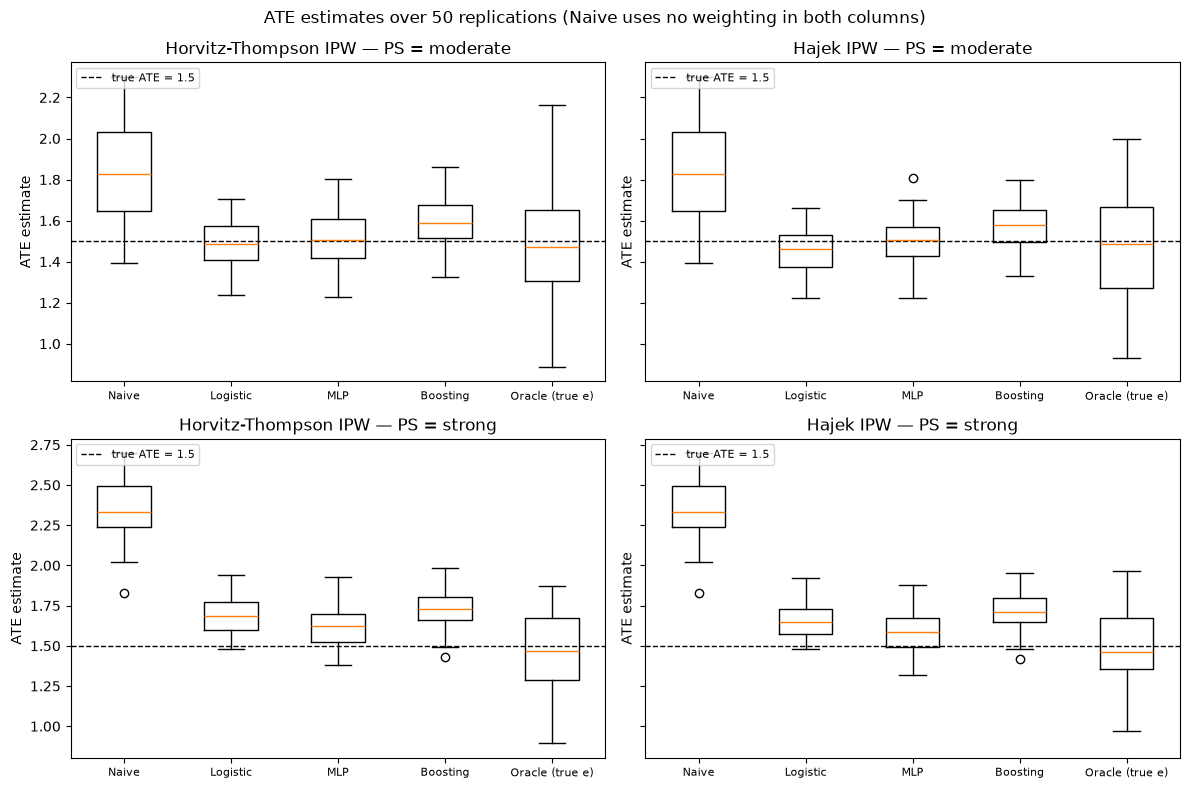

In [11]:
# (a) Distribution of ATE estimates across replications
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey="row")
for i, (col, name) in enumerate([("ht", "Horvitz-Thompson IPW"), ("hajek", "Hajek IPW")]):
    for j, ps in enumerate(PS_SCENARIOS):
        ax = axes[j, i]
        sub = est[est.ps == ps]
        ax.boxplot([sub[sub.method == m][col] for m in METHODS])
        ax.set_xticks(range(1, len(METHODS) + 1), [LABEL[m] for m in METHODS], fontsize=8)
        ax.axhline(TRUE_ATE, color="k", ls="--", lw=1, label=f"true ATE = {TRUE_ATE}")
        ax.set_title(f"{name} — PS = {ps}")
        ax.set_ylabel("ATE estimate")
        ax.legend(loc="upper left", fontsize=8)
fig.suptitle(f"ATE estimates over {R} replications (Naive uses no weighting in both columns)")
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part2_ate_boxplot.png", dpi=150)
plt.show()

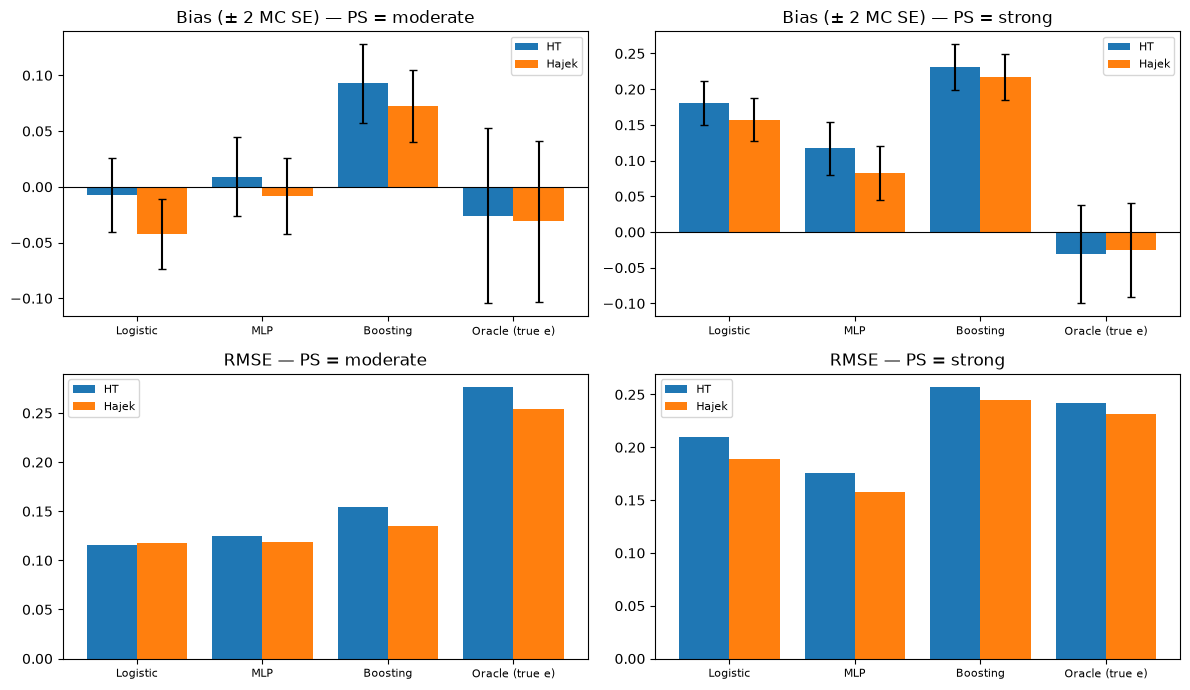

In [12]:
# (b) Bias (± 2 MC SE) and RMSE, HT and Hajek
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
meths = [m for m in METHODS if m != "naive"]       # naive bias is off the scale; reported in the table
x = np.arange(len(meths))
for j, ps in enumerate(PS_SCENARIOS):
    for k, (summ, name, off) in enumerate([(summ_ht, "HT", -0.2), (summ_hj, "Hajek", 0.2)]):
        s = summ[summ.ps == ps].set_index("method").loc[[LABEL[m] for m in meths]]
        axes[0, j].bar(x + off, s.bias, width=0.4, yerr=2*s.mc_se, capsize=3, label=name)
        axes[1, j].bar(x + off, s.rmse, width=0.4, label=name)
    axes[0, j].axhline(0, color="k", lw=0.8)
    axes[0, j].set_title(f"Bias (± 2 MC SE) — PS = {ps}")
    axes[1, j].set_title(f"RMSE — PS = {ps}")
    for ax in axes[:, j]:
        ax.set_xticks(x, [LABEL[m] for m in meths], fontsize=8)
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part2_bias_rmse.png", dpi=150)
plt.show()

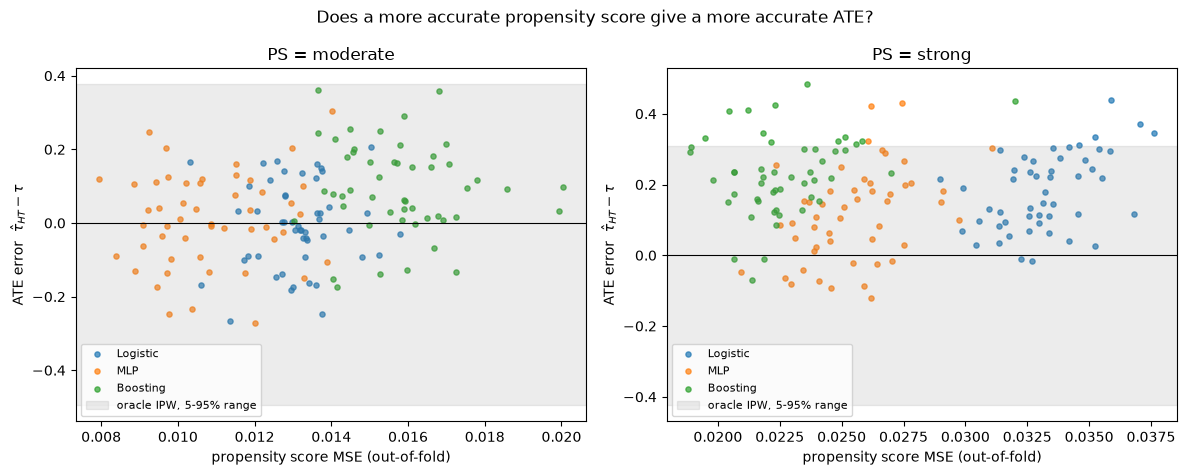

In [13]:
# (c) Propensity score MSE (Part 1) vs ATE error (Part 2), one point per replication
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, ps in zip(axes, PS_SCENARIOS):
    for m in PS_MODELS:
        s = est[(est.ps == ps) & (est.method == m)]
        ax.scatter(s.ps_mse, s.ht - TRUE_ATE, s=14, alpha=.7, label=LABEL[m])
    o = est[(est.ps == ps) & (est.method == "oracle")]
    ax.axhspan(*np.quantile(o.ht - TRUE_ATE, [.05, .95]), color="grey", alpha=.15,
               label="oracle IPW, 5-95% range")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("propensity score MSE (out-of-fold)")
    ax.set_ylabel("ATE error  $\\hat\\tau_{HT} - \\tau$")
    ax.set_title(f"PS = {ps}")
    ax.legend(fontsize=8)
fig.suptitle("Does a more accurate propensity score give a more accurate ATE?")
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part2_psmse_vs_ate_error.png", dpi=150)
plt.show()

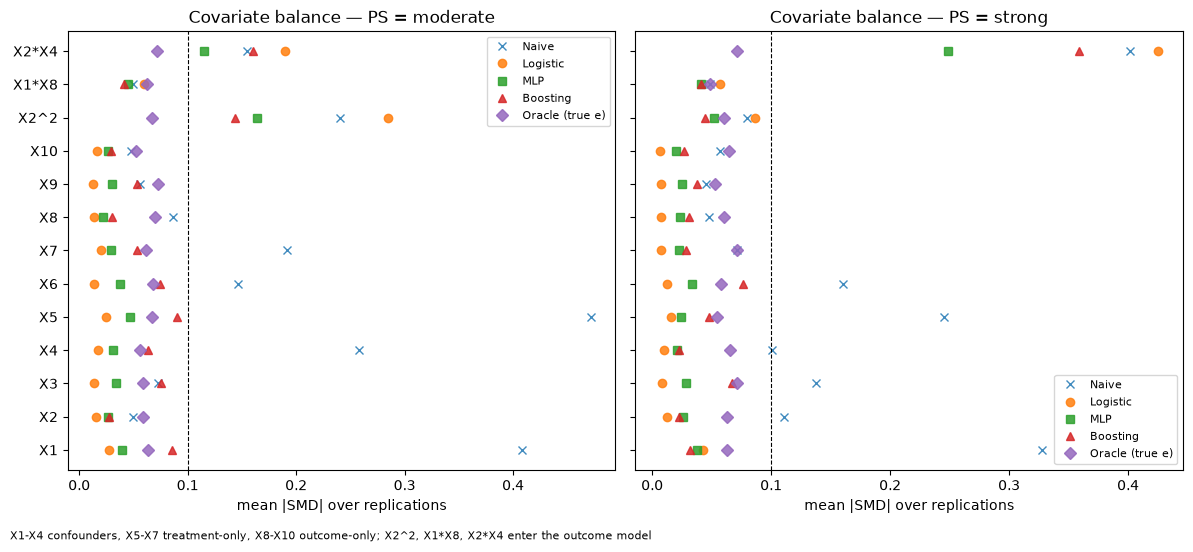

In [14]:
# (d) Love plot: mean |SMD| per covariate / nonlinear term after weighting
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
ypos = np.arange(len(BAL_NAMES))
markers = {"naive": "x", "logistic": "o", "mlp": "s", "gbm": "^", "oracle": "D"}
for ax, ps in zip(axes, PS_SCENARIOS):
    s = smd_long[smd_long.ps == ps].assign(abs_smd=lambda d: d.smd.abs())
    for m in METHODS:
        v = s[s.method == m].groupby("feature", sort=False).abs_smd.mean().loc[BAL_NAMES]
        ax.plot(v.values, ypos, markers[m], label=LABEL[m], alpha=.85)
    ax.axvline(0.1, color="k", ls="--", lw=0.8)
    ax.set_yticks(ypos, BAL_NAMES)
    ax.invert_yaxis()
    ax.set_xlabel("mean |SMD| over replications")
    ax.set_title(f"Covariate balance — PS = {ps}")
    ax.legend(fontsize=8)
fig.text(0.01, 0.01, "X1-X4 confounders, X5-X7 treatment-only, X8-X10 outcome-only; "
         "X2^2, X1*X8, X2*X4 enter the outcome model", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(RES_DIR / "fig_part2_balance.png", dpi=150)
plt.show()

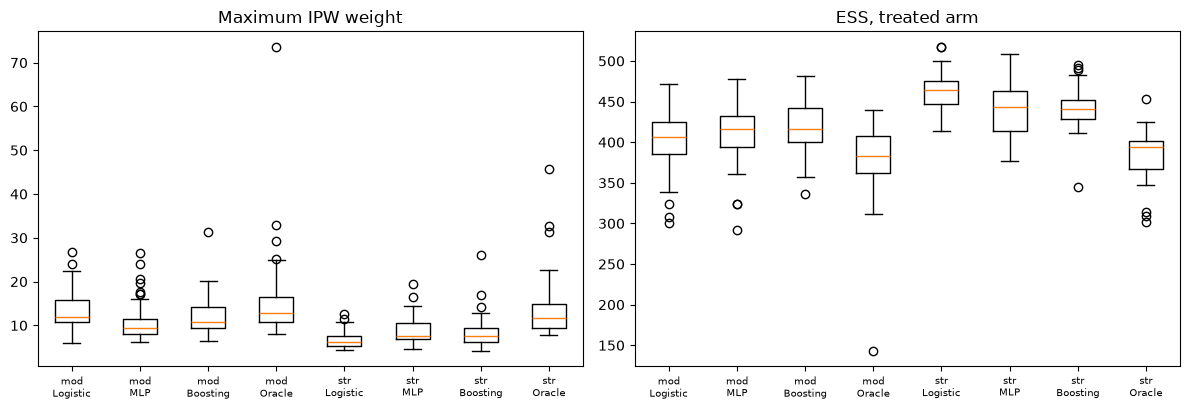

In [15]:
# (e) Weight diagnostics
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
wm = [m for m in METHODS if m != "naive"]
for ax, col, ttl in [(axes[0], "max_w", "Maximum IPW weight"),
                     (axes[1], "ess_treated", "ESS, treated arm")]:
    data, labels = [], []
    for ps in PS_SCENARIOS:
        for m in wm:
            data.append(est[(est.ps == ps) & (est.method == m)][col])
            labels.append(f"{ps[:3]}\n{LABEL[m].split(' ')[0]}")
    ax.boxplot(data)
    ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=7)
    ax.set_title(ttl)
fig.tight_layout()
fig.savefig(RES_DIR / "fig_part2_weights.png", dpi=150)
plt.show()

## 7. Sensitivity analysis: clipping $\hat e$ to [0.01, 0.99]

In [16]:
clip_rows = []
for col in ["ht", "ht_clip", "hajek", "hajek_clip"]:
    s = summarize(est[est.method != "naive"], col)
    s.insert(0, "estimator", col)
    clip_rows.append(s[["estimator", "ps", "method", "bias", "sd", "rmse"]])
clip_tab = pd.concat(clip_rows).pivot_table(index=["ps", "method"], columns="estimator",
                                            values="rmse", sort=False)
n_clip = est.n_clipped.sum()
if n_clip == 0:
    print(f"No propensity score (estimated or true) fell outside [{CLIP}, {1 - CLIP}] in any "
          "replication, so clipping changes nothing: with good overlap, trimming is not needed.")
else:
    print(f"{int(n_clip)} unit-replications clipped. RMSE with and without clipping:")
    print(clip_tab.round(4))

No propensity score (estimated or true) fell outside [0.01, 0.99] in any replication, so clipping changes nothing: with good overlap, trimming is not needed.
